<a href="https://colab.research.google.com/github/Janhavi-Srinivasan/chess-blunder-risk-model/blob/main/Chess_blunder_with_nn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
PROJECT_DIR = Path("/content/drive/MyDrive/chess-blunder-project")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)

CSV_PATH = PROJECT_DIR / "blunder_dataset_clean.csv"

Load and validate

In [ ]:
df = pd.read_csv(CSV_PATH)

print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nNulls:\n", df.isnull().sum().sort_values(ascending=False).head(20))
print("\nis_blunder distribution:\n", df['is_blunder'].value_counts(normalize=True))

dup_rows = df.duplicated().sum()
print(f"\nExact duplicate rows: {dup_rows}")

dup_moves = df.duplicated(subset=['game_id', 'move_num', 'mover_color']).sum()
print(f"Duplicate (game_id, move_num, mover_color) combos: {dup_moves}")

print("\nwp_before range:", df['wp_before'].min(), df['wp_before'].max())
print("wp_after range:", df['wp_after'].min(), df['wp_after'].max())
print("wp_drop range:", df['wp_drop'].min(), df['wp_drop'].max())
print("clock_seconds range:", df['clock_seconds'].min(), df['clock_seconds'].max())
print("time_spent range:", df['time_spent'].min(), df['time_spent'].max())
print("legal_moves_count range:", df['legal_moves_count'].min(), df['legal_moves_count'].max())

neg_time = (df['time_spent'] < 0).sum()
print(f"\nRows with negative time_spent: {neg_time}")

print(f"\nUnique games: {df['game_id'].nunique()}")
print(f"Rows per game (avg): {df.shape[0] / df['game_id'].nunique():.1f}")


try:
    import joblib
    old_feature_cols = joblib.load(PROJECT_DIR / "feature_columns.joblib")
    leaky = [c for c in ['wp_after', 'wp_drop'] if c in old_feature_cols]
    print(f"\nfeature_columns.joblib loaded, {len(old_feature_cols)} features")
    print("Potential leakage columns present in feature set:", leaky if leaky else "None — good")
except FileNotFoundError:
    print("\nfeature_columns.joblib not found in PROJECT_DIR (optional, skip if not present)")

Shape: (21058, 32)

Dtypes:
 move_num                     int64
move                        object
mover_color                  int64
wp_before                  float64
wp_after                   float64
wp_drop                    float64
is_blunder                   int64
legal_moves_count            int64
material_balance_before      int64
piece_count                  int64
game_phase                  object
was_in_check                 int64
gives_check                  int64
is_capture                   int64
clock_seconds              float64
time_spent                 float64
game_id                      int64
mover_elo                    int64
opponent_elo                 int64
elo_diff                     int64
has_clock                    int64
is_low_time                  int64
time_pressure_ratio        float64
phase_endgame                 bool
phase_middlegame              bool
phase_opening                 bool
wp_before_bucket            object
wp_losing                 

Univariate+bivariate

In [ ]:
core_features = ['time_spent', 'clock_seconds', 'legal_moves_count',
                  'material_balance_before', 'wp_before', 'time_pressure_ratio', 'elo_diff']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, feat in zip(axes.flatten(), core_features):
    df[df.is_blunder == 0][feat].hist(bins=50, alpha=0.5, label='no blunder', ax=ax, density=True)
    df[df.is_blunder == 1][feat].hist(bins=50, alpha=0.5, label='blunder', ax=ax, density=True)
    ax.set_title(feat)
    ax.legend()
plt.tight_layout()
plt.savefig(PROJECT_DIR / "step2_univariate.png", dpi=100)
plt.close()
print("\nSaved step2_univariate.png to Drive")

bins = pd.qcut(df['time_pressure_ratio'], 10, duplicates='drop')
print("\nBlunder rate by time_pressure_ratio decile:\n", df.groupby(bins)['is_blunder'].mean())

bins2 = pd.qcut(df['legal_moves_count'], 10, duplicates='drop')
print("\nBlunder rate by legal_moves_count decile:\n", df.groupby(bins2)['is_blunder'].mean())

print("\nBlunder rate by is_low_time:\n", df.groupby('is_low_time')['is_blunder'].mean())
print("\nBlunder rate by wp_before_bucket:\n", df.groupby('wp_before_bucket')['is_blunder'].mean())
print("\nBlunder rate by game_phase:\n", df.groupby('game_phase')['is_blunder'].mean())

for flag in ['was_in_check', 'gives_check', 'is_capture']:
    print(f"\nBlunder rate by {flag}:\n", df.groupby(flag)['is_blunder'].mean())



Saved step2_univariate.png to Drive

Blunder rate by time_pressure_ratio decile:
 time_pressure_ratio
(-0.001, 0.00258]     0.015180
(0.00258, 0.00426]    0.024691
(0.00426, 0.00667]    0.029370
(0.00667, 0.0089]     0.030462
(0.0089, 0.0123]      0.045109
(0.0123, 0.0172]      0.053733
(0.0172, 0.0245]      0.061283
(0.0245, 0.0368]      0.050332
(0.0368, 0.066]       0.071225
(0.066, 6.0]          0.086895
Name: is_blunder, dtype: float64

Blunder rate by legal_moves_count decile:
 legal_moves_count
(0.999, 7.0]    0.021570
(7.0, 20.0]     0.021315
(20.0, 24.0]    0.037011
(24.0, 28.0]    0.036463
(28.0, 30.0]    0.033084
(30.0, 33.0]    0.048518
(33.0, 35.0]    0.057669
(35.0, 38.0]    0.062443
(38.0, 42.0]    0.066538
(42.0, 67.0]    0.094574
Name: is_blunder, dtype: float64

Blunder rate by is_low_time:
 is_low_time
0    0.046455
1    0.068571
Name: is_blunder, dtype: float64

Blunder rate by wp_before_bucket:
 wp_before_bucket
balanced    0.043375
better      0.099174
losing    

/tmp/ipykernel_562/3636582487.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print("\nBlunder rate by time_pressure_ratio decile:\n", df.groupby(bins)['is_blunder'].mean())
/tmp/ipykernel_562/3636582487.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print("\nBlunder rate by legal_moves_count decile:\n", df.groupby(bins2)['is_blunder'].mean())


Interaction — complexity x time pressure

In [ ]:
df['complexity_bin'] = pd.qcut(df['legal_moves_count'], 5, labels=False, duplicates='drop')
df['pressure_bin'] = pd.qcut(df['time_pressure_ratio'], 5, labels=False, duplicates='drop')

pivot = df.pivot_table(values='is_blunder', index='complexity_bin', columns='pressure_bin', aggfunc='mean')
plt.figure(figsize=(8, 6))
sns.heatmap(pivot, annot=True, fmt='.2%', cmap='Reds')
plt.xlabel('Time pressure (bin 0=lowest pressure)')
plt.ylabel('Legal moves count / complexity (bin 0=lowest)')
plt.title('Blunder rate: complexity x time pressure')
plt.tight_layout()
plt.savefig(PROJECT_DIR / "step3_interaction_heatmap.png", dpi=100)
plt.close()
print("\nSaved step3_interaction_heatmap.png to Drive")

df['elo_band'] = pd.cut(df['mover_elo'], bins=[0, 1400, 1800, 2200, 3000])
plt.figure(figsize=(8, 6))
for band, g in df.groupby('elo_band', observed=True):
    bins3 = pd.qcut(g['time_pressure_ratio'], 5, duplicates='drop')
    rate = g.groupby(bins3, observed=True)['is_blunder'].mean()
    plt.plot(range(len(rate)), rate.values, marker='o', label=str(band))
plt.legend()
plt.xlabel('Time pressure (low -> high, quintiles)')
plt.ylabel('Blunder rate')
plt.title('Blunder rate vs time pressure, by Elo band')
plt.tight_layout()
plt.savefig(PROJECT_DIR / "step3_elo_band_pressure.png", dpi=100)
plt.close()
print("Saved step3_elo_band_pressure.png to Drive")



Saved step3_interaction_heatmap.png to Drive
Saved step3_elo_band_pressure.png to Drive


Feature Scaling


In [ ]:
df = pd.read_csv(CSV_PATH)
df = df.sort_values(['game_id', 'move_num']).reset_index(drop=True)
LEAKY_COLS = ['wp_after', 'wp_drop']
grp = df.groupby(['game_id', 'mover_color'], group_keys=False)['time_spent']
df['own_avg_time_spent'] = grp.apply(lambda s: s.shift(1).expanding().mean())
df['own_std_time_spent'] = grp.apply(lambda s: s.shift(1).expanding().std())

df['own_avg_time_spent'] = df['own_avg_time_spent'].fillna(df['time_spent'])
df['own_std_time_spent'] = df['own_std_time_spent'].fillna(0)

df['pace_deviation'] = df['time_spent'] - df['own_avg_time_spent']
df['pace_deviation_z'] = df['pace_deviation'] / (df['own_std_time_spent'] + 1e-3)


FEATURE_COLS = [
    'time_spent', 'clock_seconds', 'time_pressure_ratio', 'is_low_time',
    'own_avg_time_spent', 'own_std_time_spent', 'pace_deviation', 'pace_deviation_z',
]

assert not any(c in FEATURE_COLS for c in LEAKY_COLS), "Leakage column found in feature set!"

for c in FEATURE_COLS:
    if df[c].dtype == bool:
        df[c] = df[c].astype(int)

print("Feature set:", len(FEATURE_COLS), "columns")
print(df[FEATURE_COLS].isnull().sum().sum(), "total nulls in feature set")

Feature set: 8 columns
0 total nulls in feature set


Sequence construction: window of last N moves BY THE SAME PLAYER

In [ ]:
WINDOW = 6

def build_sequences(df, feature_cols, window=WINDOW):
    X_seq, y_seq, meta = [], [], []
    for (game_id, color), g in df.groupby(['game_id', 'mover_color']):
        g = g.sort_values('move_num')
        feats = g[feature_cols].values
        labels = g['is_blunder'].values
        n = len(g)
        for i in range(n):
            start = max(0, i - window + 1)
            window_feats = feats[start:i+1]
            if len(window_feats) < window:
                pad = np.zeros((window - len(window_feats), len(feature_cols)))
                window_feats = np.vstack([pad, window_feats])
            X_seq.append(window_feats)
            y_seq.append(labels[i])
            meta.append(game_id)
    return np.array(X_seq, dtype=np.float32), np.array(y_seq, dtype=np.float32), np.array(meta)

X_seq, y_seq, game_ids_arr = build_sequences(df, FEATURE_COLS, WINDOW)
print("Sequence tensor shape:", X_seq.shape)   # (n_samples, window, n_features)
print("Label shape:", y_seq.shape, "  positive rate:", y_seq.mean())

Sequence tensor shape: (21058, 6, 8)
Label shape: (21058,)   positive rate: 0.04682306


train test split and scale

In [ ]:
unique_games = df['game_id'].unique()
rng = np.random.RandomState(42)
rng.shuffle(unique_games)

n = len(unique_games)
train_games = set(unique_games[:int(0.7*n)])
val_games = set(unique_games[int(0.7*n):int(0.85*n)])
test_games = set(unique_games[int(0.85*n):])

train_mask = np.isin(game_ids_arr, list(train_games))
val_mask = np.isin(game_ids_arr, list(val_games))
test_mask = np.isin(game_ids_arr, list(test_games))

X_train, y_train = X_seq[train_mask], y_seq[train_mask]
X_val, y_val = X_seq[val_mask], y_seq[val_mask]
X_test, y_test = X_seq[test_mask], y_seq[test_mask]

print(f"\nTrain: {X_train.shape[0]} sequences, {y_train.mean():.3%} positive")
print(f"Val:   {X_val.shape[0]} sequences, {y_val.mean():.3%} positive")
print(f"Test:  {X_test.shape[0]} sequences, {y_test.mean():.3%} positive")


from sklearn.preprocessing import StandardScaler

n_feat = X_train.shape[2]
scaler = StandardScaler()
scaler.fit(X_train.reshape(-1, n_feat))

def scale(X):
    shape = X.shape
    return scaler.transform(X.reshape(-1, n_feat)).reshape(shape).astype(np.float32)

X_train_s, X_val_s, X_test_s = scale(X_train), scale(X_val), scale(X_test)

np.savez(PROJECT_DIR / "sequence_data.npz",
         X_train=X_train_s, y_train=y_train,
         X_val=X_val_s, y_val=y_val,
         X_test=X_test_s, y_test=y_test)

import joblib
joblib.dump(FEATURE_COLS, PROJECT_DIR / "nn_feature_columns.joblib")
joblib.dump(scaler, PROJECT_DIR / "nn_feature_scaler.joblib")

print("\nSaved sequence_data.npz, nn_feature_columns.joblib, nn_feature_scaler.joblib to", PROJECT_DIR)


Train: 14747 sequences, 4.801% positive
Val:   3497 sequences, 4.118% positive
Test:  2814 sequences, 4.762% positive

Saved sequence_data.npz, nn_feature_columns.joblib, nn_feature_scaler.joblib to /content/drive/MyDrive/chess-blunder-project


In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report

torch.manual_seed(42)
np.random.seed(42)

data = np.load(PROJECT_DIR / "sequence_data.npz")
X_train, y_train = data['X_train'], data['y_train']
X_val, y_val = data['X_val'], data['y_val']
X_test, y_test = data['X_test'], data['y_test']

n_samples, window, n_feat = X_train.shape
print(f"Window={window}, n_features={n_feat}")

Window=6, n_features=8


Dataset Loader

In [ ]:
class SeqDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_ds = SeqDataset(X_train, y_train)
val_ds = SeqDataset(X_val, y_val)
test_ds = SeqDataset(X_test, y_test)

# Weighted sampler to counter class imbalance (~4-5% positive)
class_counts = np.bincount(y_train.astype(int))
class_weights = 1.0 / class_counts
sample_weights = class_weights[y_train.astype(int)]
sampler = torch.utils.data.WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

train_loader = DataLoader(train_ds, batch_size=64, sampler=sampler)
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False)

pos_weight = torch.tensor([class_counts[0] / class_counts[1]], dtype=torch.float32)


Model 1: MLP baseline — flattens the window, ignores sequence order

In [ ]:
class MLPBaseline(nn.Module):
    def __init__(self, window, n_feat, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(window * n_feat, hidden),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden // 2, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


Model 2: LSTM — models the sequence, this is the "human behavior" model

In [ ]:
class LSTMBlunderModel(nn.Module):
    def __init__(self, n_feat, hidden=64, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, num_layers=num_layers, batch_first=True, dropout=0.0)
        self.head = nn.Sequential(
            nn.Linear(hidden, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 1),
        )
    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        last_hidden = out[:, -1, :]
        return self.head(last_hidden).squeeze(-1)

Training loop (shared for both models)

In [ ]:
def train_model(model, train_loader, val_loader, epochs=25, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    best_val_ap = 0
    best_state = None

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * xb.size(0)
        train_loss /= len(train_loader.dataset)

        model.eval()
        val_probs, val_true = [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                logits = model(xb)
                probs = torch.sigmoid(logits)
                val_probs.append(probs.numpy())
                val_true.append(yb.numpy())
        val_probs = np.concatenate(val_probs)
        val_true = np.concatenate(val_true)
        val_ap = average_precision_score(val_true, val_probs)
        val_auc = roc_auc_score(val_true, val_probs)

        if val_ap > best_val_ap:
            best_val_ap = val_ap
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        if epoch % 5 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch:2d} | train_loss={train_loss:.4f} | val_PR-AUC={val_ap:.4f} | val_ROC-AUC={val_auc:.4f}")

    model.load_state_dict(best_state)
    return model, best_val_ap

def evaluate(model, loader, name=""):
    model.eval()
    probs, true = [], []
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb)
            probs.append(torch.sigmoid(logits).numpy())
            true.append(yb.numpy())
    probs = np.concatenate(probs)
    true = np.concatenate(true)
    ap = average_precision_score(true, probs)
    auc = roc_auc_score(true, probs)
    print(f"\n[{name}] PR-AUC={ap:.4f}  ROC-AUC={auc:.4f}  (baseline PR-AUC if random = {true.mean():.4f})")
    preds = (probs > 0.5).astype(int)
    print(classification_report(true, preds, target_names=['no_blunder', 'blunder'], zero_division=0))
    return ap, auc

In [ ]:
print("\n" + "="*60)
print("MODEL 1: MLP baseline (flattened window, no sequence structure)")
print("="*60)
mlp = MLPBaseline(window, n_feat)
mlp, mlp_val_ap = train_model(mlp, train_loader, val_loader, epochs=25)
evaluate(mlp, test_loader, "MLP - TEST")

print("\n" + "="*60)
print("MODEL 2: LSTM (models the move-by-move sequence)")
print("="*60)
lstm = LSTMBlunderModel(n_feat, hidden=64, num_layers=1)
lstm, lstm_val_ap = train_model(lstm, train_loader, val_loader, epochs=25)
evaluate(lstm, test_loader, "LSTM - TEST")

print("\n" + "="*60)
print(f"SUMMARY — Val PR-AUC:  MLP={mlp_val_ap:.4f}   LSTM={lstm_val_ap:.4f}")
print("="*60)

torch.save(mlp.state_dict(), PROJECT_DIR / "mlp_baseline.pt")
torch.save(lstm.state_dict(), PROJECT_DIR / "lstm_blunder_model.pt")
print("\nSaved mlp_baseline.pt and lstm_blunder_model.pt to", PROJECT_DIR)


MODEL 1: MLP baseline (flattened window, no sequence structure)
Epoch  0 | train_loss=2.7222 | val_PR-AUC=0.0638 | val_ROC-AUC=0.6309
Epoch  5 | train_loss=1.8834 | val_PR-AUC=0.0637 | val_ROC-AUC=0.6090
Epoch 10 | train_loss=1.8468 | val_PR-AUC=0.0651 | val_ROC-AUC=0.6160
Epoch 15 | train_loss=1.8235 | val_PR-AUC=0.0688 | val_ROC-AUC=0.6208
Epoch 20 | train_loss=1.8026 | val_PR-AUC=0.0699 | val_ROC-AUC=0.6242
Epoch 24 | train_loss=1.7736 | val_PR-AUC=0.0651 | val_ROC-AUC=0.6074

[MLP - TEST] PR-AUC=0.0796  ROC-AUC=0.6626  (baseline PR-AUC if random = 0.0476)
              precision    recall  f1-score   support

  no_blunder       1.00      0.09      0.16      2680
     blunder       0.05      0.99      0.10       134

    accuracy                           0.13      2814
   macro avg       0.52      0.54      0.13      2814
weighted avg       0.95      0.13      0.16      2814


MODEL 2: LSTM (models the move-by-move sequence)
Epoch  0 | train_loss=2.5934 | val_PR-AUC=0.0663 | val_R

PR Curve ROC curve

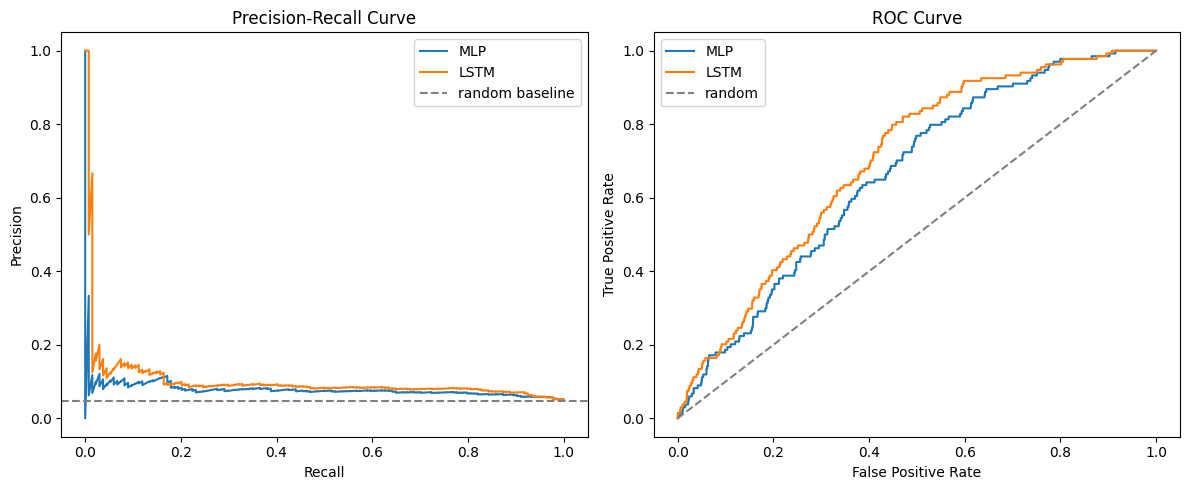

Saved pr_roc_curves.png to Drive


In [ ]:
import traceback
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve
def get_probs(model, loader):
    model.eval()
    probs, true = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(torch.sigmoid(model(xb)).numpy())
            true.append(yb.numpy())
    return np.concatenate(probs), np.concatenate(true)

mlp_probs, test_true = get_probs(mlp, test_loader)
lstm_probs, _ = get_probs(lstm, test_loader)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Precision-Recall curve
for probs, label in [(mlp_probs, "MLP"), (lstm_probs, "LSTM")]:
    prec, rec, _ = precision_recall_curve(test_true, probs)
    axes[0].plot(rec, prec, label=label)
axes[0].axhline(test_true.mean(), color='gray', linestyle='--', label='random baseline')
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-Recall Curve"); axes[0].legend()

# ROC curve
for probs, label in [(mlp_probs, "MLP"), (lstm_probs, "LSTM")]:
    fpr, tpr, _ = roc_curve(test_true, probs)
    axes[1].plot(fpr, tpr, label=label)
axes[1].plot([0,1],[0,1], color='gray', linestyle='--', label='random')
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve"); axes[1].legend()

plt.tight_layout()
plt.savefig(PROJECT_DIR / "pr_roc_curves.png", dpi=100)
plt.show()
print("Saved pr_roc_curves.png to Drive")


GRAPH 2: "Danger curve" — predicted blunder risk across one real game, with actual blunders marked. THIS is the direct visual answer to "how do we know about blunder from behavior".

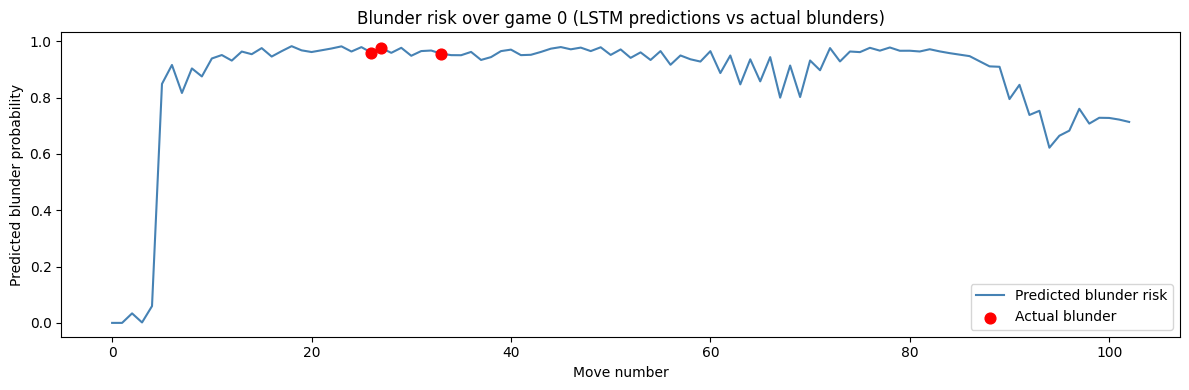

Saved danger_curve_sample_game.png to Drive


In [ ]:
sample_game_id = df['game_id'].unique()[0]
g = df[df['game_id'] == sample_game_id].sort_values('move_num')

seqs, move_nums, true_labels = [], [], []
for color in g['mover_color'].unique():
    gc = g[g['mover_color'] == color].sort_values('move_num')
    feats = gc[FEATURE_COLS].values
    labels = gc['is_blunder'].values
    move_nums_c = gc['move_num'].values
    for i in range(len(gc)):
        start = max(0, i - WINDOW + 1)
        w = feats[start:i+1]
        if len(w) < WINDOW:
            pad = np.zeros((WINDOW - len(w), len(FEATURE_COLS)))
            w = np.vstack([pad, w])
        seqs.append(w)
        move_nums.append(move_nums_c[i])
        true_labels.append(labels[i])

seqs = np.array(seqs, dtype=np.float32)
seqs_scaled = scaler.transform(seqs.reshape(-1, n_feat)).reshape(seqs.shape).astype(np.float32)

lstm.eval()
with torch.no_grad():
    risk = torch.sigmoid(lstm(torch.tensor(seqs_scaled))).numpy()

order = np.argsort(move_nums)
move_nums_sorted = np.array(move_nums)[order]
risk_sorted = risk[order]
true_sorted = np.array(true_labels)[order]

plt.figure(figsize=(12, 4))
plt.plot(move_nums_sorted, risk_sorted, label="Predicted blunder risk", color='steelblue')
blunder_moves = move_nums_sorted[true_sorted == 1]
blunder_risk = risk_sorted[true_sorted == 1]
plt.scatter(blunder_moves, blunder_risk, color='red', zorder=5, label="Actual blunder", s=60)
plt.xlabel("Move number")
plt.ylabel("Predicted blunder probability")
plt.title(f"Blunder risk over game {sample_game_id} (LSTM predictions vs actual blunders)")
plt.legend()
plt.tight_layout()
plt.savefig(PROJECT_DIR / "danger_curve_sample_game.png", dpi=100)
plt.show()
print("Saved danger_curve_sample_game.png to Drive")


window= 3 | val PR-AUC=0.0800 ± 0.0005 | test PR-AUC=0.0947
window= 4 | val PR-AUC=0.0750 ± 0.0018 | test PR-AUC=0.0891
window= 5 | val PR-AUC=0.0705 ± 0.0026 | test PR-AUC=0.0957
window= 6 | val PR-AUC=0.0671 ± 0.0033 | test PR-AUC=0.0927
window= 8 | val PR-AUC=0.0666 ± 0.0023 | test PR-AUC=0.1033
window=10 | val PR-AUC=0.0671 ± 0.0017 | test PR-AUC=0.1049
window=12 | val PR-AUC=0.0674 ± 0.0023 | test PR-AUC=0.1065
window=15 | val PR-AUC=0.0681 ± 0.0020 | test PR-AUC=0.1042

  window  val_PR_AUC  val_std  test_PR_AUC  test_ROC_AUC
      3    0.079989 0.000467     0.094735      0.694319
      4    0.074970 0.001764     0.089119      0.680611
      5    0.070497 0.002597     0.095665      0.687359
      6    0.067066 0.003335     0.092703      0.690750
      8    0.066616 0.002343     0.103298      0.700550
     10    0.067059 0.001658     0.104879      0.705095
     12    0.067419 0.002279     0.106541      0.707992
     15    0.068131 0.002016     0.104229      0.704315

Best window b

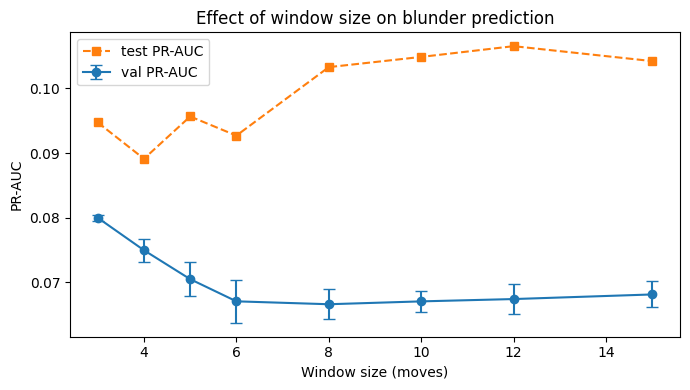

In [ ]:
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score

WINDOWS = [3, 4, 5, 6, 8, 10, 12, 15]
SEEDS   = [0, 1, 2]          # average over seeds because 300 games = noisy
EPOCHS, PATIENCE = 20, 5

# ---------- data + behavior-only features (same as colab_2) ----------
df = pd.read_csv(PROJECT_DIR / "blunder_dataset_clean.csv")
df = df.sort_values(['game_id', 'move_num']).reset_index(drop=True)
grp = df.groupby(['game_id', 'mover_color'], group_keys=False)['time_spent']
df['own_avg_time_spent'] = grp.apply(lambda s: s.shift(1).expanding().mean())
df['own_std_time_spent'] = grp.apply(lambda s: s.shift(1).expanding().std())
df['own_avg_time_spent'] = df['own_avg_time_spent'].fillna(df['time_spent'])
df['own_std_time_spent'] = df['own_std_time_spent'].fillna(0)
df['pace_deviation']   = df['time_spent'] - df['own_avg_time_spent']
df['pace_deviation_z'] = df['pace_deviation'] / (df['own_std_time_spent'] + 1e-3)
FEATS = ['time_spent', 'clock_seconds', 'time_pressure_ratio', 'is_low_time',
         'own_avg_time_spent', 'own_std_time_spent', 'pace_deviation', 'pace_deviation_z']
for c in FEATS:
    if df[c].dtype == bool: df[c] = df[c].astype(int)

# ---------- same game-level split for every window ----------
games = df['game_id'].unique()
np.random.RandomState(42).shuffle(games)
n = len(games)
tr_g, va_g, te_g = set(games[:int(.7*n)]), set(games[int(.7*n):int(.85*n)]), set(games[int(.85*n):])

def build(window):
    X, y, gid = [], [], []
    for (g, c), d in df.groupby(['game_id', 'mover_color']):
        d = d.sort_values('move_num')
        f, l = d[FEATS].values, d['is_blunder'].values
        for i in range(len(d)):
            w = f[max(0, i - window + 1): i + 1]
            if len(w) < window:
                w = np.vstack([np.zeros((window - len(w), len(FEATS))), w])
            X.append(w); y.append(l[i]); gid.append(g)
    X, y, gid = np.array(X, np.float32), np.array(y, np.float32), np.array(gid)
    m = [np.isin(gid, list(s)) for s in (tr_g, va_g, te_g)]
    sc = StandardScaler().fit(X[m[0]].reshape(-1, len(FEATS)))
    S = lambda A: sc.transform(A.reshape(-1, len(FEATS))).reshape(A.shape).astype(np.float32)
    return S(X[m[0]]), y[m[0]], S(X[m[1]]), y[m[1]], S(X[m[2]]), y[m[2]]

class LSTMModel(nn.Module):
    def __init__(self, nf, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(nf, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(32, 1))
    def forward(self, x):
        o, _ = self.lstm(x)
        return self.head(o[:, -1, :]).squeeze(-1)

def predict(m, X):
    m.eval()
    with torch.no_grad():
        return torch.sigmoid(m(torch.tensor(X))).numpy()

def run(Xtr, ytr, Xv, yv, Xte, yte, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    cnt = np.bincount(ytr.astype(int))
    w = (1.0 / cnt)[ytr.astype(int)]
    loader = DataLoader(TensorDataset(torch.tensor(Xtr), torch.tensor(ytr)), batch_size=64,
                        sampler=WeightedRandomSampler(w, len(w), replacement=True))
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([cnt[0] / cnt[1]], dtype=torch.float32))
    m = LSTMModel(Xtr.shape[2])
    opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-5)
    best, state, bad = 0.0, None, 0
    for _ in range(EPOCHS):
        m.train()
        for xb, yb in loader:
            opt.zero_grad(); crit(m(xb), yb).backward(); opt.step()
        ap = average_precision_score(yv, predict(m, Xv))      # validation only
        if ap > best:
            best, bad = ap, 0
            state = {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    m.load_state_dict(state)
    p = predict(m, Xte)
    return best, average_precision_score(yte, p), roc_auc_score(yte, p)

# ---------- search over window size ----------
rows = []
for W in WINDOWS:
    data = build(W)
    out = np.array([run(*data, seed=s) for s in SEEDS])
    rows.append({'window': W,
                 'val_PR_AUC':  out[:, 0].mean(), 'val_std': out[:, 0].std(),
                 'test_PR_AUC': out[:, 1].mean(), 'test_ROC_AUC': out[:, 2].mean()})
    print(f"window={W:2d} | val PR-AUC={out[:,0].mean():.4f} ± {out[:,0].std():.4f} "
          f"| test PR-AUC={out[:,1].mean():.4f}")

res = pd.DataFrame(rows)
res.to_csv(PROJECT_DIR / "window_tuning.csv", index=False)
best_w = int(res.loc[res['val_PR_AUC'].idxmax(), 'window'])
print("\n", res.to_string(index=False))
print(f"\nBest window by VALIDATION PR-AUC: {best_w}")

# ---------- plot ----------
plt.figure(figsize=(7, 4))
plt.errorbar(res['window'], res['val_PR_AUC'], yerr=res['val_std'], marker='o', capsize=4, label='val PR-AUC')
plt.plot(res['window'], res['test_PR_AUC'], marker='s', linestyle='--', label='test PR-AUC')
plt.xlabel("Window size (moves)"); plt.ylabel("PR-AUC"); plt.legend()
plt.title("Effect of window size on blunder prediction")
plt.tight_layout()
plt.savefig(PROJECT_DIR / "window_tuning.png", dpi=100); plt.show()

            band  n_moves  n_games  n_blunders  blunder_rate  PR_AUC  lift_vs_random      lift_CI  ROC_AUC         ROC_CI
 low (1402-1507)     2092       32          91         0.043   0.073           1.687 [1.28, 2.52]    0.648 [0.580, 0.714]
 mid (1508-1615)     2058       43          97         0.047   0.085           1.806 [1.49, 2.69]    0.657 [0.609, 0.708]
high (1616-1798)     2161       43          90         0.042   0.102           2.452 [1.43, 4.05]    0.693 [0.622, 0.758]


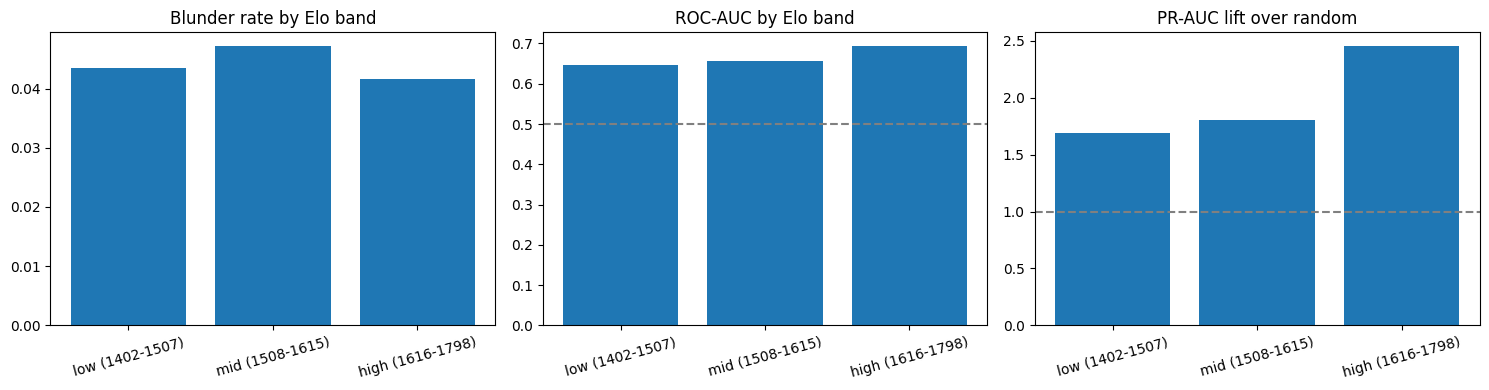

In [ ]:
import json
import numpy as np, pandas as pd, torch, torch.nn as nn, joblib
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score

WINDOW = 6
N_BANDS = 3
EVAL_SPLITS = {"val", "test"}
N_BOOT = 300
df = pd.read_csv(PROJECT_DIR / "blunder_dataset_clean.csv")
df = df.sort_values(['game_id', 'move_num']).reset_index(drop=True)
grp = df.groupby(['game_id', 'mover_color'], group_keys=False)['time_spent']
df['own_avg_time_spent'] = grp.apply(lambda s: s.shift(1).expanding().mean())
df['own_std_time_spent'] = grp.apply(lambda s: s.shift(1).expanding().std())
df['own_avg_time_spent'] = df['own_avg_time_spent'].fillna(df['time_spent'])
df['own_std_time_spent'] = df['own_std_time_spent'].fillna(0)
df['pace_deviation']   = df['time_spent'] - df['own_avg_time_spent']
df['pace_deviation_z'] = df['pace_deviation'] / (df['own_std_time_spent'] + 1e-3)

FEATS = joblib.load(PROJECT_DIR / "nn_feature_columns.joblib")
scaler = joblib.load(PROJECT_DIR / "nn_feature_scaler.joblib")
for c in FEATS:
    if df[c].dtype == bool: df[c] = df[c].astype(int)

X, y, gid, elo = [], [], [], []
for (g, c), d in df.groupby(['game_id', 'mover_color']):
    d = d.sort_values('move_num')
    f, l, e = d[FEATS].values, d['is_blunder'].values, d['mover_elo'].values
    for i in range(len(d)):
        w = f[max(0, i - WINDOW + 1): i + 1]
        if len(w) < WINDOW:
            w = np.vstack([np.zeros((WINDOW - len(w), len(FEATS))), w])
        X.append(w); y.append(l[i]); gid.append(g); elo.append(e[i])
X, y = np.array(X, np.float32), np.array(y, np.float32)
gid, elo = np.array(gid), np.array(elo, dtype=float)
nf = X.shape[2]
X = scaler.transform(X.reshape(-1, nf)).reshape(X.shape).astype(np.float32)
games = df['game_id'].unique()
np.random.RandomState(42).shuffle(games)
n = len(games)
split_of = {}
for g in games[:int(.7 * n)]:             split_of[g] = "train"
for g in games[int(.7 * n):int(.85 * n)]: split_of[g] = "val"
for g in games[int(.85 * n):]:            split_of[g] = "test"
mask = np.array([split_of[g] in EVAL_SPLITS for g in gid])
X, y, gid, elo = X[mask], y[mask], gid[mask], elo[mask]
class LSTMBlunderModel(nn.Module):
    def __init__(self, n_feat, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(32, 1))
    def forward(self, x):
        o, _ = self.lstm(x)
        return self.head(o[:, -1, :]).squeeze(-1)

try:
    model = lstm
except NameError:
    model = LSTMBlunderModel(nf)
    model.load_state_dict(torch.load(PROJECT_DIR / "lstm_blunder_model.pt"))
model.eval()
with torch.no_grad():
    probs = torch.sigmoid(model(torch.tensor(X))).numpy()
edges = np.quantile(elo, np.linspace(0, 1, N_BANDS + 1))
edges[0], edges[-1] = edges[0] - 1, edges[-1] + 1
band = np.digitize(elo, edges[1:-1])
labels = [f"{int(edges[i])+1 if i else int(edges[0])+1}-{int(edges[i+1])}" for i in range(N_BANDS)]
names = ["low", "mid", "high"] if N_BANDS == 3 else [f"band{i}" for i in range(N_BANDS)]

def boot_ci(idx, metric, n_boot=N_BOOT, seed=0):
    """Bootstrap over GAMES (moves in one game are not independent)."""
    rng = np.random.RandomState(seed)
    by_game = {}
    for i in idx: by_game.setdefault(gid[i], []).append(i)
    gl = list(by_game)
    vals = []
    for _ in range(n_boot):
        pick = np.concatenate([by_game[gl[j]] for j in rng.randint(0, len(gl), len(gl))])
        if 0 < y[pick].sum() < len(pick):
            vals.append(metric(y[pick], probs[pick]))
    return np.percentile(vals, [2.5, 97.5]) if vals else (np.nan, np.nan)

rows = []
for b in range(N_BANDS):
    idx = np.where(band == b)[0]
    base = y[idx].mean()
    pr, roc = average_precision_score(y[idx], probs[idx]), roc_auc_score(y[idx], probs[idx])
    roc_lo, roc_hi = boot_ci(idx, roc_auc_score)
    lift_lo, lift_hi = boot_ci(idx, lambda yt, p: average_precision_score(yt, p) / yt.mean())
    rows.append({"band": f"{names[b]} ({labels[b]})", "n_moves": len(idx),
                 "n_games": len(set(gid[idx])), "n_blunders": int(y[idx].sum()),
                 "blunder_rate": base, "PR_AUC": pr, "lift_vs_random": pr / base,
                 "lift_CI": f"[{lift_lo:.2f}, {lift_hi:.2f}]",
                 "ROC_AUC": roc, "ROC_CI": f"[{roc_lo:.3f}, {roc_hi:.3f}]"})

res = pd.DataFrame(rows)
res.to_csv(PROJECT_DIR / "skill_band_analysis.csv", index=False)
print(res.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# ---------- plot ----------
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
x = np.arange(N_BANDS)
ax[0].bar(x, res["blunder_rate"]); ax[0].set_title("Blunder rate by Elo band")
ax[1].bar(x, res["ROC_AUC"]);      ax[1].set_title("ROC-AUC by Elo band"); ax[1].axhline(0.5, ls="--", c="gray")
ax[2].bar(x, res["lift_vs_random"]); ax[2].set_title("PR-AUC lift over random"); ax[2].axhline(1, ls="--", c="gray")
for a in ax:
    a.set_xticks(x); a.set_xticklabels(res["band"], rotation=15)
plt.tight_layout(); plt.savefig(PROJECT_DIR / "skill_band_analysis.png", dpi=100); plt.show()

##1. Setup, features, split, scaling

In [1]:
!pip install optuna chess -q
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
import torch, torch.nn as nn
from pathlib import Path
from numpy.lib.stride_tricks import sliding_window_view
from google.colab import drive
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, roc_curve, classification_report)

drive.mount('/content/drive')
PROJECT_DIR = Path("/content/drive/MyDrive/chess-blunder-project")
SEED, WINDOW = 42, 6
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print("device:", DEVICE)
PLAYER_COL = None      # set to a mover/player id column for a true player-level split, else game-level

df = pd.read_csv(PROJECT_DIR / "blunder_dataset_clean.csv").sort_values(['game_id', 'move_num']).reset_index(drop=True)

# ---- same leak-safe pace features as your original notebook
g = df.groupby(['game_id', 'mover_color'])['time_spent']
df['own_avg_time_spent'] = g.transform(lambda s: s.shift(1).expanding().mean()).fillna(df['time_spent'])
df['own_std_time_spent'] = g.transform(lambda s: s.shift(1).expanding().std()).fillna(0)
df['pace_deviation'] = df['time_spent'] - df['own_avg_time_spent']
df['pace_deviation_z'] = df['pace_deviation'] / (df['own_std_time_spent'] + 1e-3)

for c in ['is_low_time', 'was_in_check']:
    df[c] = df[c].astype(int)
df = df.drop(columns=[c for c in df.columns if c.startswith('phase_')])
df = pd.get_dummies(df, columns=['game_phase'], prefix='phase', dtype=int)
df = df.loc[:, ~df.columns.duplicated()]
PHASE = [c for c in df.columns if c.startswith('phase_')]
df['elo_band'] = pd.cut(df['mover_elo'], [0, 1400, 1800, 2200, 3000], labels=['<1400', '1400-1800', '1800-2200', '2200+']).astype(str)

# ---- feature groups (wp_after / wp_drop / gives_check / is_capture excluded to avoid leakage)
ORIGINAL = ['time_spent', 'clock_seconds', 'time_pressure_ratio', 'is_low_time',
            'own_avg_time_spent', 'own_std_time_spent', 'pace_deviation', 'pace_deviation_z']       # your original 8
TIME_ABS = ['time_spent', 'clock_seconds', 'time_pressure_ratio', 'is_low_time']
PACE     = ['own_avg_time_spent', 'own_std_time_spent', 'pace_deviation', 'pace_deviation_z']
POS      = ['legal_moves_count', 'wp_before', 'material_balance_before', 'was_in_check', 'elo_diff', 'move_num'] + PHASE
FULL     = ORIGINAL + POS

# ---- group split (70/15/15)
groups = df[PLAYER_COL] if PLAYER_COL else df['game_id']
i_tr, i_tmp = next(GroupShuffleSplit(1, test_size=0.30, random_state=SEED).split(df, groups=groups))
i_va, i_te = next(GroupShuffleSplit(1, test_size=0.50, random_state=SEED).split(df.iloc[i_tmp], groups=groups.iloc[i_tmp]))
df['split'] = 'train'
df.loc[df.index[i_tmp][i_va], 'split'] = 'val'
df.loc[df.index[i_tmp][i_te], 'split'] = 'test'
print(df.groupby('split')['is_blunder'].agg(['size', 'mean']).round(4))

# ---- scale on TRAIN rows only; padding is added after scaling (see build())
scaler = StandardScaler().fit(df.loc[df.split == 'train', FULL])
dfs = df[['game_id', 'mover_color', 'move_num', 'is_blunder', 'split']].copy()
dfs[FULL] = scaler.transform(df[FULL]).astype(np.float32)
joblib.dump((FULL, scaler), PROJECT_DIR / "cog_feature_scaler.joblib")
GROUP_IDX = df.groupby(['game_id', 'mover_color']).indices       # positional row indices, ordered by move_num

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive
device: cpu
        size    mean
split               
test    3351  0.0463
train  14693  0.0474
val     3014  0.0445


##

## 2. Sequence builder, models, training (same architecture as your original code)

In [2]:
_CACHE = {}
def get_data(cols, window):
    """Sliding windows per (game, player). Early moves are zero-padded AFTER scaling and flagged by an is_pad channel."""
    key = (tuple(cols), window)
    if key in _CACHE: return _CACHE[key]
    arr, F = dfs[cols].values, len(cols)
    Xs, idxs = [], []
    for pos in GROUP_IDX.values():
        padded = np.zeros((len(pos) + window - 1, F + 1), np.float32)
        padded[:window - 1, F] = 1.0
        padded[window - 1:, :F] = arr[pos]
        Xs.append(sliding_window_view(padded, window, axis=0).transpose(0, 2, 1)); idxs.append(pos)
    X, idx = np.concatenate(Xs), np.concatenate(idxs)
    y, sp = dfs['is_blunder'].values[idx].astype(np.float32), dfs['split'].values[idx]
    d = {s: (torch.tensor(X[sp == s]).to(DEVICE), torch.tensor(y[sp == s]).to(DEVICE)) for s in ['train', 'val', 'test']}
    d['idx'] = {s: idx[sp == s] for s in ['train', 'val', 'test']}
    _CACHE.clear(); _CACHE[key] = d          # keep only one cached tensor set to save memory
    return d

class MLPBaseline(nn.Module):
    def __init__(self, window, n_feat, hidden=64, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(window * n_feat, hidden), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden // 2, 1))
    def forward(self, x): return self.net(x).squeeze(-1)

class LSTMBlunderModel(nn.Module):
    def __init__(self, n_feat, hidden=64, num_layers=1, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, num_layers=num_layers, batch_first=True, dropout=dropout if num_layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1))
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)

@torch.no_grad()
def predict(model, X, bs=4096):
    model.eval()
    return np.concatenate([torch.sigmoid(model(X[i:i + bs])).cpu().numpy() for i in range(0, len(X), bs)])

def run(kind, cols, window=WINDOW, hidden=64, layers=1, dropout=0.3, lr=1e-3, wd=1e-5, batch=256,
        epochs=30, patience=5, seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed)
    d = get_data(cols, window)
    (Xtr, ytr), (Xva, yva), (Xte, yte) = d['train'], d['val'], d['test']
    nf = Xtr.shape[2]
    model = (MLPBaseline(window, nf, hidden, dropout) if kind == 'mlp' else LSTMBlunderModel(nf, hidden, layers, dropout)).to(DEVICE)
    pos_w = ((ytr == 0).sum() / (ytr == 1).sum()).reshape(1)                # the ONLY imbalance correction
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=2)
    best, best_state, bad = -1, None, 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr), device=DEVICE)
        for i in range(0, len(perm), batch):
            b = perm[i:i + batch]
            opt.zero_grad(); loss = crit(model(Xtr[b]), ytr[b]); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        ap = average_precision_score(yva.cpu().numpy(), predict(model, Xva))
        sched.step(ap)
        if ap > best: best, best_state, bad = ap, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    return dict(model=model, val_ap=best, p_val=predict(model, Xva), p_test=predict(model, Xte),
                y_val=yva.cpu().numpy(), y_test=yte.cpu().numpy(), idx=d['idx'])

def scores(y, p):
    return dict(PR_AUC=average_precision_score(y, p), ROC_AUC=roc_auc_score(y, p))
print("ready")

ready


##3. Does adding positional features help? (original 8 features vs extended)

In [3]:
rows = []
for name, cols in [('Original (timing only)', ORIGINAL), ('Timing + positional', FULL)]:
    for kind in ['mlp', 'lstm']:
        r = run(kind, cols)
        rows.append(dict(features=name, model=kind.upper(), val_PR=round(r['val_ap'], 4), **{k: round(v, 4) for k, v in scores(r['y_test'], r['p_test']).items()}))
cmp_ = pd.DataFrame(rows); print(cmp_); print("random PR-AUC baseline:", round(df[df.split == 'test'].is_blunder.mean(), 4))
cmp_.to_csv(PROJECT_DIR / "cog_feature_comparison.csv", index=False)

                 features model  val_PR  PR_AUC  ROC_AUC
0  Original (timing only)   MLP  0.0711  0.0896   0.6659
1  Original (timing only)  LSTM  0.0778  0.0916   0.6713
2     Timing + positional   MLP  0.1290  0.1371   0.7603
3     Timing + positional  LSTM  0.1463  0.1543   0.7741
random PR-AUC baseline: 0.0463


##4. Panic isolation with the LSTM (feature-group ablation)

                               PR_AUC         ROC_AUC        
                                 mean     std    mean     std
feature_set                                                  
Time only                      0.0852  0.0059  0.6605  0.0153
Position only                  0.1447  0.0039  0.7509  0.0115
Pace / panic only              0.0903  0.0012  0.6573  0.0007
Time + Position                0.1676  0.0046  0.7765  0.0046
Time + Position + Pace (full)  0.1564  0.0027  0.7728  0.0014

Panic contribution (full - Time+Position): PR-AUC -0.0112


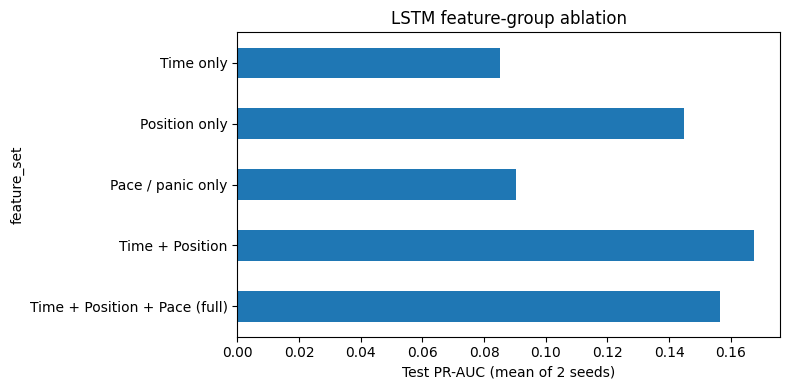

In [4]:
sets = {'Time only': TIME_ABS, 'Position only': POS, 'Pace / panic only': PACE,
        'Time + Position': TIME_ABS + POS, 'Time + Position + Pace (full)': TIME_ABS + POS + PACE}
rows = []
for name, cols in sets.items():
    for s in [1, 2]:
        r = run('lstm', cols, seed=s)
        rows.append(dict(feature_set=name, seed=s, **scores(r['y_test'], r['p_test'])))
ab = pd.DataFrame(rows).groupby('feature_set', sort=False).agg(['mean', 'std']).round(4)
print(ab[['PR_AUC', 'ROC_AUC']])
ab.to_csv(PROJECT_DIR / "cog_lstm_ablation.csv")
m = ab[('PR_AUC', 'mean')]
print(f"\nPanic contribution (full - Time+Position): PR-AUC {m['Time + Position + Pace (full)'] - m['Time + Position']:+.4f}")
m[::-1].plot.barh(figsize=(8, 4)); plt.xlabel('Test PR-AUC (mean of 2 seeds)'); plt.title('LSTM feature-group ablation')
plt.tight_layout(); plt.savefig(PROJECT_DIR / "cog_lstm_ablation.png", dpi=100); plt.show()

##5. Window-size sweep (how much history matters)

   window  val_PR  PR_AUC  ROC_AUC
0       3  0.1586  0.1691   0.7734
1       6  0.1463  0.1543   0.7741
2      10  0.1517  0.1424   0.7689
3      15  0.1519  0.1428   0.7695


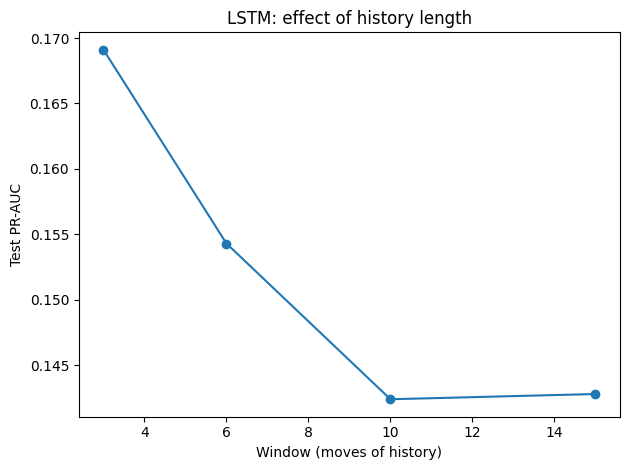

In [6]:
rows = []
for w in [3, 6, 10, 15]:
    r = run('lstm', FULL, window=w)
    rows.append(dict(window=w, val_PR=r['val_ap'], **scores(r['y_test'], r['p_test'])))
sw = pd.DataFrame(rows).round(4); print(sw); sw.to_csv(PROJECT_DIR / "cog_window_sweep.csv", index=False)
plt.plot(sw.window, sw.PR_AUC, marker='o'); plt.xlabel('Window (moves of history)'); plt.ylabel('Test PR-AUC')
plt.title('LSTM: effect of history length'); plt.tight_layout(); plt.savefig(PROJECT_DIR / "cog_window_sweep.png", dpi=100); plt.show()

##6. Optuna tuning for the LSTM (validation PR-AUC only)

In [7]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
TUNE_WINDOW = WINDOW      # set to the best window from section 5 if different

def objective(t):
    r = run('lstm', FULL, window=TUNE_WINDOW,
            hidden=t.suggest_categorical('hidden', [32, 64, 128]), layers=t.suggest_int('layers', 1, 2),
            dropout=t.suggest_float('dropout', 0.0, 0.5), lr=t.suggest_float('lr', 3e-4, 3e-3, log=True),
            wd=t.suggest_float('wd', 1e-6, 1e-3, log=True), batch=t.suggest_categorical('batch', [128, 256, 512]),
            epochs=12, patience=3)
    return r['val_ap']

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=12, show_progress_bar=True)
print("best val PR-AUC:", round(study.best_value, 4), study.best_params)
json.dump({**study.best_params, 'window': TUNE_WINDOW}, open(PROJECT_DIR / "lstm_best_params.json", "w"))

  0%|          | 0/12 [00:00<?, ?it/s]

best val PR-AUC: 0.1551 {'hidden': 64, 'layers': 2, 'dropout': 0.12938999080000846, 'lr': 0.001379251735419649, 'wd': 8.61257919259488e-06, 'batch': 256}


##7. Final evaluation: 3 seeds, calibration, validation-selected threshold, per-band results

MLP over 3 seeds: PR-AUC 0.1464 ± 0.0087 | ROC-AUC 0.7691 ± 0.0076
LSTM over 3 seeds: PR-AUC 0.1515 ± 0.0078 | ROC-AUC 0.7757 ± 0.0040

[MLP] ensemble TEST PR-AUC=0.1251 ROC-AUC=0.7671 Brier raw=0.1570 -> calibrated=0.0421  (threshold 0.138)
              precision    recall  f1-score   support

  no_blunder       0.96      0.95      0.95      3196
     blunder       0.18      0.25      0.21       155

    accuracy                           0.91      3351
   macro avg       0.57      0.60      0.58      3351
weighted avg       0.93      0.91      0.92      3351


[LSTM] ensemble TEST PR-AUC=0.1237 ROC-AUC=0.7683 Brier raw=0.1548 -> calibrated=0.0420  (threshold 0.121)
              precision    recall  f1-score   support

  no_blunder       0.97      0.86      0.91      3196
     blunder       0.13      0.43      0.20       155

    accuracy                           0.84      3351
   macro avg       0.55      0.65      0.56      3351
weighted avg       0.93      0.84      0.88      33

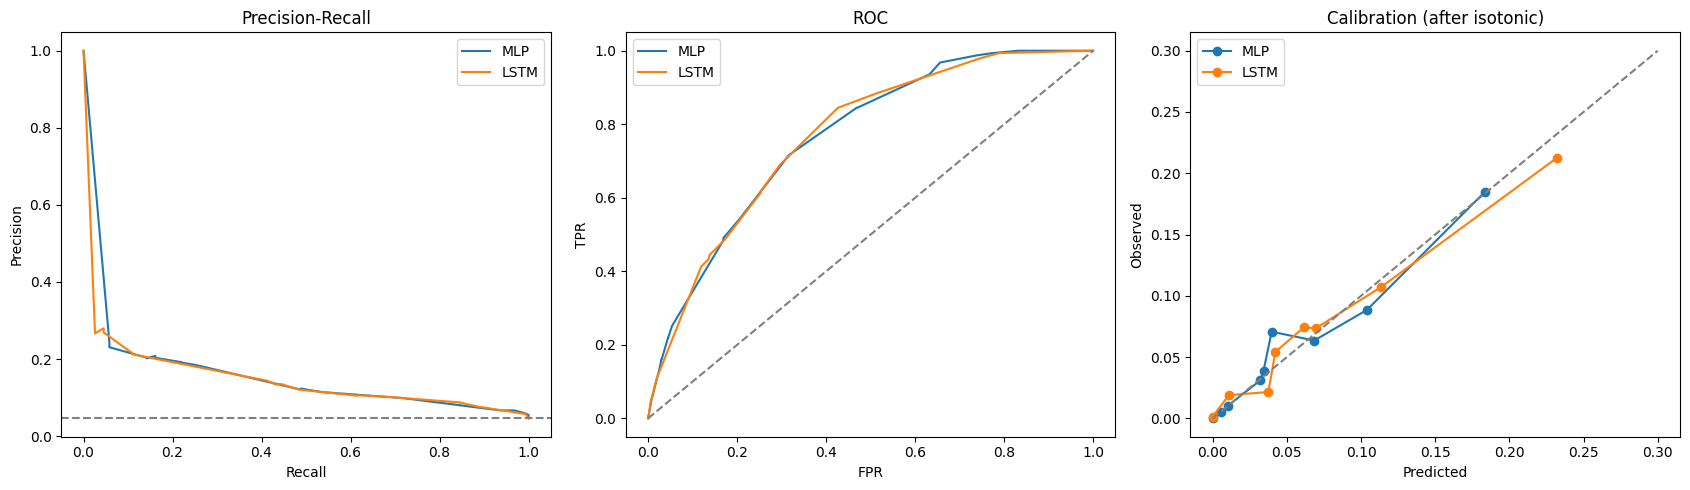

        band     n  blunder_rate  PR_AUC  ROC_AUC
0  1400-1800  3293        0.0471  0.1244   0.7676


In [8]:
pf = PROJECT_DIR / "lstm_best_params.json"
hp = json.load(open(pf)) if pf.exists() else {}
win = hp.pop('window', WINDOW)
SEEDS = [1, 2, 3]
runs = {k: [run(k, FULL, window=win, seed=s, **(hp if k == 'lstm' else {})) for s in SEEDS] for k in ['mlp', 'lstm']}

for k, rs in runs.items():
    t = pd.DataFrame([scores(r['y_test'], r['p_test']) for r in rs])
    print(f"{k.upper()} over {len(SEEDS)} seeds: PR-AUC {t.PR_AUC.mean():.4f} ± {t.PR_AUC.std():.4f} | ROC-AUC {t.ROC_AUC.mean():.4f} ± {t.ROC_AUC.std():.4f}")

# ensemble the seeds, calibrate on validation, pick threshold on validation, then touch test once
final = {}
for k, rs in runs.items():
    pv, pt = np.mean([r['p_val'] for r in rs], 0), np.mean([r['p_test'] for r in rs], 0)
    iso = IsotonicRegression(out_of_bounds='clip').fit(pv, rs[0]['y_val'])
    pv_c, pt_c = iso.predict(pv), iso.predict(pt)
    pr, rc, th = precision_recall_curve(rs[0]['y_val'], pv_c); f1 = 2 * pr * rc / (pr + rc + 1e-9)
    thr = th[np.argmax(f1[:-1])]
    y = rs[0]['y_test']
    final[k] = dict(p_test=pt, p_cal=pt_c, y=y, thr=thr, idx=rs[0]['idx']['test'])
    print(f"\n[{k.upper()}] ensemble TEST PR-AUC={average_precision_score(y, pt_c):.4f} ROC-AUC={roc_auc_score(y, pt_c):.4f} "
          f"Brier raw={brier_score_loss(y, np.clip(pt, 0, 1)):.4f} -> calibrated={brier_score_loss(y, pt_c):.4f}  (threshold {thr:.3f})")
    print(classification_report(y, (pt_c >= thr).astype(int), target_names=['no_blunder', 'blunder'], zero_division=0))

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for k, f in final.items():
    pr, rc, _ = precision_recall_curve(f['y'], f['p_cal']); ax[0].plot(rc, pr, label=k.upper())
    fp, tp, _ = roc_curve(f['y'], f['p_cal']); ax[1].plot(fp, tp, label=k.upper())
    a, b = calibration_curve(f['y'], f['p_cal'], n_bins=10, strategy='quantile'); ax[2].plot(b, a, marker='o', label=k.upper())
ax[0].axhline(final['lstm']['y'].mean(), ls='--', c='gray'); ax[0].set(title='Precision-Recall', xlabel='Recall', ylabel='Precision')
ax[1].plot([0, 1], [0, 1], ls='--', c='gray'); ax[1].set(title='ROC', xlabel='FPR', ylabel='TPR')
ax[2].plot([0, .3], [0, .3], ls='--', c='gray'); ax[2].set(title='Calibration (after isotonic)', xlabel='Predicted', ylabel='Observed')
for a in ax: a.legend()
plt.tight_layout(); plt.savefig(PROJECT_DIR / "cog_final_curves.png", dpi=100); plt.show()

# performance by rating band (the cross-band research question)
f = final['lstm']; bands = df['elo_band'].values[f['idx']]
rows = [dict(band=b, n=int((bands == b).sum()), blunder_rate=f['y'][bands == b].mean(), **scores(f['y'][bands == b], f['p_cal'][bands == b]))
        for b in ['<1400', '1400-1800', '1800-2200', '2200+'] if (bands == b).sum() > 200 and f['y'][bands == b].sum() > 10]
print(pd.DataFrame(rows).round(4))

##8. Danger curve (+ board renderings at the riskiest moves if a FEN column exists)

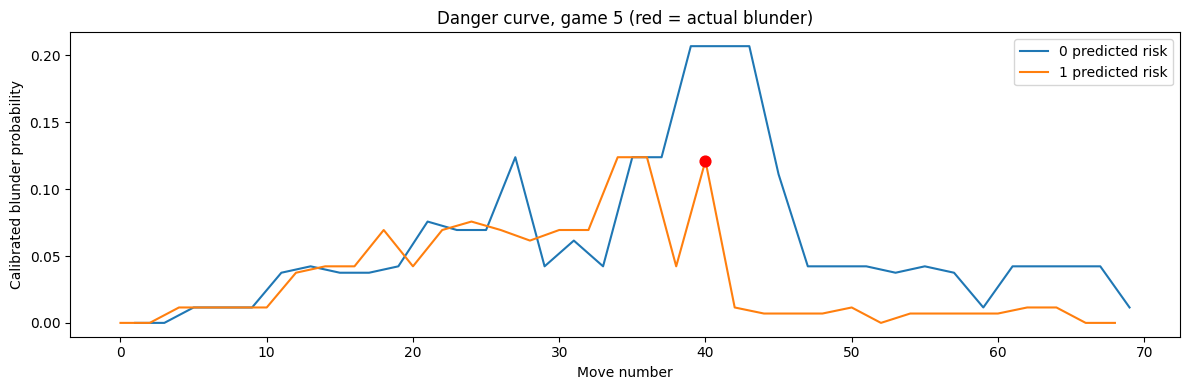

No FEN column in the CSV. To render boards, store the FEN before each move in the labelling pipeline (board.fen() inside the Stockfish labelling loop) and re-export the CSV.


In [9]:
import chess, chess.svg
from IPython.display import display, SVG
f = final['lstm']
risk = pd.Series(f['p_cal'], index=f['idx'])                           # df row position -> calibrated risk
test_games = df.loc[f['idx'], 'game_id'].unique()
gid = test_games[0]                                                    # change index to look at other games
gd = df[df.game_id == gid]; gd = gd[gd.index.isin(risk.index)].assign(risk=lambda x: risk.loc[x.index].values)

plt.figure(figsize=(12, 4))
for color, gc in gd.groupby('mover_color'):
    plt.plot(gc.move_num, gc.risk, label=f'{color} predicted risk')
    bl = gc[gc.is_blunder == 1]; plt.scatter(bl.move_num, bl.risk, c='red', s=60, zorder=5)
plt.xlabel('Move number'); plt.ylabel('Calibrated blunder probability')
plt.title(f'Danger curve, game {gid} (red = actual blunder)'); plt.legend(); plt.tight_layout()
plt.savefig(PROJECT_DIR / "cog_danger_curve.png", dpi=100); plt.show()

fen_col = next((c for c in df.columns if c.lower() in ('fen', 'fen_before', 'position_fen')), None)
if fen_col:
    for _, row in gd.sort_values('risk', ascending=False).head(3).iterrows():
        print(f"move {int(row.move_num)} ({row.mover_color}) risk={row.risk:.2f} blunder={int(row.is_blunder)}")
        display(SVG(chess.svg.board(chess.Board(row[fen_col]), size=320)))
else:
    print("No FEN column in the CSV. To render boards, store the FEN before each move in the labelling pipeline "
          "(board.fen() inside the Stockfish labelling loop) and re-export the CSV.")

##

## 9. Skill-band analysis with honest out-of-fold predictions
Every game gets a prediction from a model that never trained on it (5-fold grouped CV), so all games can be used for the band comparison
instead of val+test of a model that was early-stopped on val. Includes a paired game-level bootstrap for the *difference* between bands.

In [10]:
pf = PROJECT_DIR / "lstm_best_params.json"
hp = json.load(open(pf)) if pf.exists() else {}
win = hp.pop('window', WINDOW)
K = 5
ug = df['game_id'].unique(); np.random.RandomState(SEED).shuffle(ug)
fold_arr = df['game_id'].map({g: i % K for i, g in enumerate(ug)}).values
oof = np.full(len(df), np.nan)
orig_split = dfs['split'].copy()
for k in range(K):
    dfs['split'] = np.where(fold_arr == k, 'test', np.where(fold_arr == (k + 1) % K, 'val', 'train'))
    _CACHE.clear()
    r = run('lstm', FULL, window=win, seed=SEED, **hp)
    oof[r['idx']['test']] = r['p_test']
    print(f"fold {k}: PR-AUC={average_precision_score(r['y_test'], r['p_test']):.4f}")
dfs['split'] = orig_split; _CACHE.clear()

ok = ~np.isnan(oof)
y, p, gid, elo = df['is_blunder'].values[ok], oof[ok], df['game_id'].values[ok], df['mover_elo'].values[ok]
print(f"\nOOF overall PR-AUC={average_precision_score(y, p):.4f} ROC-AUC={roc_auc_score(y, p):.4f} | Elo range in data: {elo.min():.0f}-{elo.max():.0f}")
N_BANDS = 3
edges = np.quantile(elo, np.linspace(0, 1, N_BANDS + 1)); edges[0] -= 1; edges[-1] += 1
band = np.digitize(elo, edges[1:-1]); names = [f"band{b} ({edges[b]:.0f}-{edges[b+1]:.0f})" for b in range(N_BANDS)]

by_game = {}
for i, g_ in enumerate(gid): by_game.setdefault(g_, []).append(i)
gl, rng = list(by_game), np.random.RandomState(0)
boot = []
for _ in range(300):
    pick = np.concatenate([by_game[gl[j]] for j in rng.randint(0, len(gl), len(gl))])
    row = []
    for b in range(N_BANDS):
        q = pick[band[pick] == b]
        row.append(roc_auc_score(y[q], p[q]) if 0 < y[q].sum() < len(q) else np.nan)
    boot.append(row)
boot = np.array(boot)

rows = []
for b in range(N_BANDS):
    m = band == b
    lo, hi = np.nanpercentile(boot[:, b], [2.5, 97.5])
    rows.append(dict(band=names[b], n_moves=int(m.sum()), n_games=len(set(gid[m])), n_blunders=int(y[m].sum()),
                     blunder_rate=y[m].mean(), PR_AUC=average_precision_score(y[m], p[m]),
                     lift=average_precision_score(y[m], p[m]) / y[m].mean(), ROC_AUC=roc_auc_score(y[m], p[m]),
                     ROC_CI=f"[{lo:.3f}, {hi:.3f}]"))
res = pd.DataFrame(rows); print(res.round(4).to_string(index=False)); res.to_csv(PROJECT_DIR / "cog_band_analysis_oof.csv", index=False)
diff = boot[:, -1] - boot[:, 0]
print(f"\nROC-AUC (highest band - lowest band): {np.nanmean(diff):+.4f}, 95% CI [{np.nanpercentile(diff, 2.5):+.4f}, {np.nanpercentile(diff, 97.5):+.4f}] "
      f"-> {'differs' if np.nanpercentile(diff, 2.5) > 0 or np.nanpercentile(diff, 97.5) < 0 else 'no clear difference'}")

fold 0: PR-AUC=0.1058
fold 1: PR-AUC=0.1226
fold 2: PR-AUC=0.1681
fold 3: PR-AUC=0.1401
fold 4: PR-AUC=0.1643

OOF overall PR-AUC=0.1343 ROC-AUC=0.7626 | Elo range in data: 1400-1799
             band  n_moves  n_games  n_blunders  blunder_rate  PR_AUC   lift  ROC_AUC         ROC_CI
band0 (1399-1510)     6997      113         323        0.0462  0.1254 2.7163   0.7608 [0.733, 0.791]
band1 (1510-1630)     7040      140         353        0.0501  0.1536 3.0625   0.7658 [0.738, 0.796]
band2 (1630-1800)     7021      122         310        0.0442  0.1323 2.9972   0.7608 [0.731, 0.791]

ROC-AUC (highest band - lowest band): -0.0012, 95% CI [-0.0434, +0.0393] -> no clear difference
